**Asif Mohammadi (yrq8vu), Mason Riffee (hmr2xq), Jacob Stallard (dvy9gc), Aaron Witzel (asy3fx)**

### Given sales function

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

### Labs grid search and gradient ascent

In [ ]:
def estimate_gradient(price, *, step = 1.0, mean_customers = 300, rng = None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low,
                            mean_customers = mean_customers,
                            rng = rng)
    high = price_high * sales(price_high,
                              mean_customers = mean_customers,
                              rng = rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof = 1) / len(low) + high.var(ddof = 1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
        "revenue": low.sum() + high.sum(),
    }


def gradient_ascent(start_price,
                    iterations = 80,
                    step = 1.0,
                    learning_rate = 2.0,
                    mean_customers = 300, seed = 100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price,
                                     step = step,
                                     mean_customers = mean_customers,
                                     rng = search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1,
                        **estimate,
                        "learning_rate": rate,
                        "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

### Our grid search
- This looks at 300 customers from every 5 dollar price from 10 to 60
- finds the optimal revenue out of these fourteen prices
- then chooses this prices to perform gradient ascent

In [ ]:
total_customers = 0
total_revenue = 0.0

rows = []
for price in np.arange(10, 60.1, 5):
    revenue = sales(price,
                    mean_customers = 300,
                    rng = rng) * price
    total_customers += len(revenue)
    total_revenue += revenue.sum()
    se = np.std(revenue, ddof = 1) / np.sqrt(len(revenue))
    rows.append({'price': price,
                 'customers': len(revenue),
                 'mean': revenue.mean(),
                 'se': se})

grid = pd.DataFrame(rows)
best_grid_price = grid.loc[grid['mean'].idxmax(), 'price']
print(grid.round(3))
print(f'Best grid price: {best_grid_price}')
print(f'Customers used in grid search: {total_customers}')


    price  customers    mean     se
0    10.0        319   9.969  0.031
1    15.0        324   8.241  0.415
2    20.0        305   9.508  0.573
3    25.0        292  11.473  0.730
4    30.0        276   9.239  0.835
5    35.0        297   5.067  0.716
6    40.0        302   5.960  0.821
7    45.0        279   6.129  0.926
8    50.0        269   6.506  1.028
9    55.0        277   4.765  0.931
10   60.0        317   2.461  0.669
Best grid price: 25.0
Customers used in grid search: 3257


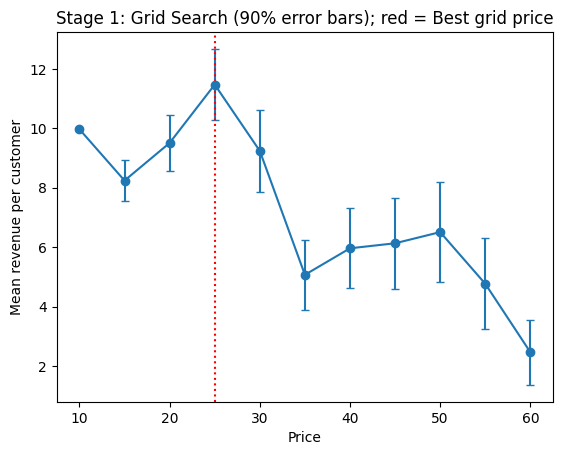

In [ ]:
#Grid search plot
plt.errorbar(grid["price"], grid["mean"], yerr=1.645 * grid["se"], fmt="o-", capsize=3)

plt.axvline(best_grid_price, color="red", linestyle=":")
plt.xlabel("Price"); plt.ylabel("Mean revenue per customer")
plt.title("Stage 1: Grid Search (90% error bars); red = Best grid price")
plt.show()


In [ ]:
total_customers_grad = [0]

path = gradient_ascent(start_price = best_grid_price,
                       iterations = 20,
                       mean_customers = 200,
                       seed = 100)
total_customers_grad += path['customers'].sum()
total_revenue += path['revenue'].sum()
total_customers += path['customers'].sum()

print(path[['iteration', 'price', 'gradient', 'ci_low', 'ci_high', 'next_price', 'customers']].round(3))
best_price = path['next_price'].iloc[-1]
print(f'Chosen price: {best_price:.2f}')
print(f'the total customers experimented on during gradient descent is {total_customers_grad[0]}')



    iteration   price  gradient  ci_low  ci_high  next_price  customers
0           1  25.000     0.481  -0.570    1.533      25.962        392
1           2  25.962     0.549  -0.509    1.607      26.739        408
2           3  26.739     1.066  -0.014    2.146      27.970        415
3           4  27.970     2.574   1.452    3.695      29.970        386
4           5  29.970    -0.458  -1.652    0.735      29.560        374
5           6  29.560    -0.632  -1.782    0.519      29.044        410
6           7  29.044    -0.116  -1.270    1.039      28.957        397
7           8  28.957    -0.332  -1.513    0.848      28.722        388
8           9  28.722    -0.934  -2.137    0.269      28.099        386
9          10  28.099    -0.266  -1.389    0.856      27.931        416
10         11  27.931    -0.005  -1.145    1.135      27.928        406
11         12  27.928    -0.668  -1.778    0.442      27.542        412
12         13  27.542     0.914  -0.221    2.049      28.050    

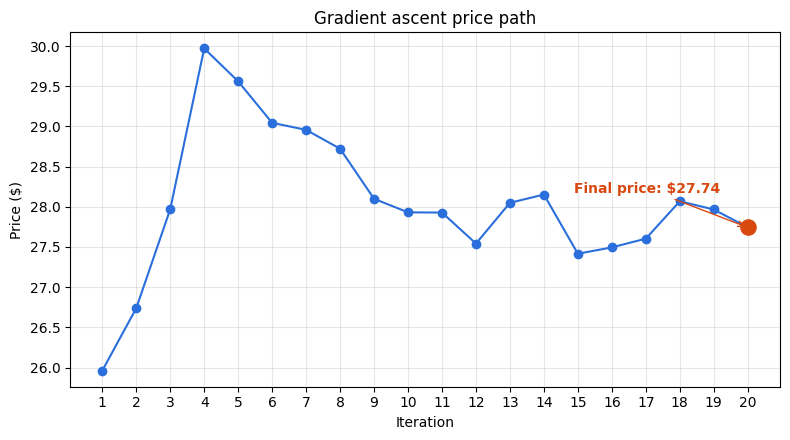

In [ ]:
#Gradient ascent plot
fig, ax = plt.subplots(figsize = (8, 4.5))
ax.plot(path['iteration'], path['next_price'], marker = 'o', color = '#2a6fdb')

final = path.iloc[-1]
ax.scatter(final['iteration'], final['next_price'], s = 120, color = '#d9480f', zorder = 3)
ax.annotate(f"Final price: ${final['next_price']:.2f}",
            xy = (final['iteration'], final['next_price']),
            xytext = (-20, 25), textcoords = 'offset points', ha = 'right',
            arrowprops = dict(arrowstyle = '->', color = '#d9480f'),
            color = '#d9480f', fontweight = 'bold')

ax.set_xlabel('Iteration')
ax.set_ylabel('Price ($)')
ax.set_title('Gradient ascent price path')
ax.set_xticks(path['iteration'])
ax.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

### Results

In [ ]:
print(f'Chosen price: {best_price:.2f}')
print(f'Total customers experimented on: {total_customers}')
print(f'Total revenue during experiments: {total_revenue:.2f}')
print(f'Revenue per customer during experiments: {total_revenue / total_customers:.3f}')

captured = best_price * purchase_probability(best_price) / 11.925
print(f'Share of optimal revenue/customer captured: {captured:.2%}')


Chosen price: 27.74
Total customers experimented on: 11178
Total revenue during experiments: 114976.89
Revenue per customer during experiments: 10.286
Share of optimal revenue/customer captured: 100.00%
